### This notebook is to plot figures for QRF paper

In [2]:
import xarray as xr
import matplotlib.pyplot as plt
import geopandas as gpd
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter
import geopandas as gpd
import utils_b as utils

In [3]:
elr_rpss_week1 = xr.open_dataset('/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_rpss_Week1_2022_2024.nc')['prcp']
elr_rpss_week2 = xr.open_dataset('/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_rpss_Week2_2022_2024.nc')['prcp']
elr_rpss_week34 = xr.open_dataset('/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_rpss_Week34_2022_2024.nc')['prcp']

In [4]:
rpss_week1 =np.load('/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/QRF_output/tuned_rpss_week_1_2022_2024.npy')
rpss_week2 =np.load('/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/QRF_output/tuned_rpss_week_2_2022_2024.npy')
rpss_week34 =np.load('/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/QRF_output/tuned_rpss_week_34_2022_2024.npy')
# Use coordinates from elr_rpss_week1
Y = elr_rpss_week1.coords["Y"]
X = elr_rpss_week1.coords["X"]
# Create DataArray with coordinates from elr_rpss_week1
qrf_rpss_week1 = xr.DataArray(rpss_week1 , dims=["Y", "X"], coords={"Y": Y, "X": X}, name="rpss")
qrf_rpss_week2 = xr.DataArray(rpss_week2 , dims=["Y", "X"], coords={"Y": Y, "X": X}, name="rpss")
qrf_rpss_week34 = xr.DataArray(rpss_week34 , dims=["Y", "X"], coords={"Y": Y, "X": X}, name="rpss")


In [5]:
def smooth_xarray_with_nan(data, sigma=1):
    nan_mask = np.isnan(data)
    filled_data = data.fillna(data.mean())
    smoothed = gaussian_filter(filled_data, sigma=sigma)
    smoothed_data = xr.DataArray(smoothed, coords=data.coords, dims=data.dims)
    smoothed_data = smoothed_data.where(~nan_mask)
    return smoothed_data


In [6]:
smqrf_rpss_week1 = smooth_xarray_with_nan(qrf_rpss_week1, sigma=1)
smqrf_rpss_week2 = smooth_xarray_with_nan(qrf_rpss_week2, sigma=1)
smqrf_rpss_week34 = smooth_xarray_with_nan(qrf_rpss_week34, sigma=1)

smelr_rpss_week1 = smooth_xarray_with_nan(elr_rpss_week1, sigma=1)
smelr_rpss_week2 = smooth_xarray_with_nan(elr_rpss_week2, sigma=1)
smelr_rpss_week34 = smooth_xarray_with_nan(elr_rpss_week34, sigma=1)

In [7]:
# Load the shapefile
shapefile_path = "/Users/bohar/Documents/ELR_IRI2/shapes/indian_borders.shp"  # Update with your actual file path
State_shapefile_path = "/Users/bohar/Documents/ELR_IRI2/shapes/sd_boundary.shp"  # Update with your actual file path
gdf = gpd.read_file(shapefile_path)
gdf_st = gpd.read_file(State_shapefile_path)

In [8]:
# List of smoothed xarray.DataArray variables (assumed to be in your environment)
rpss_var = [
    'smelr_rpss_week1', 'smelr_rpss_week2', 'smelr_rpss_week34',
    'smqrf_rpss_week1', 'smqrf_rpss_week2', 'smqrf_rpss_week34'
]

titles = [
    'ELR week-1', 'ELR week-2', 'ELR weeks 3-4',
    'QRF week-1', 'QRF week-2', 'QRF weeks 3-4'
]

/var/folders/34/fdq0mjln3bq45ggl8td4163c0000gp/T/ipykernel_34111/1660213513.py:55: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space on right for colorbar


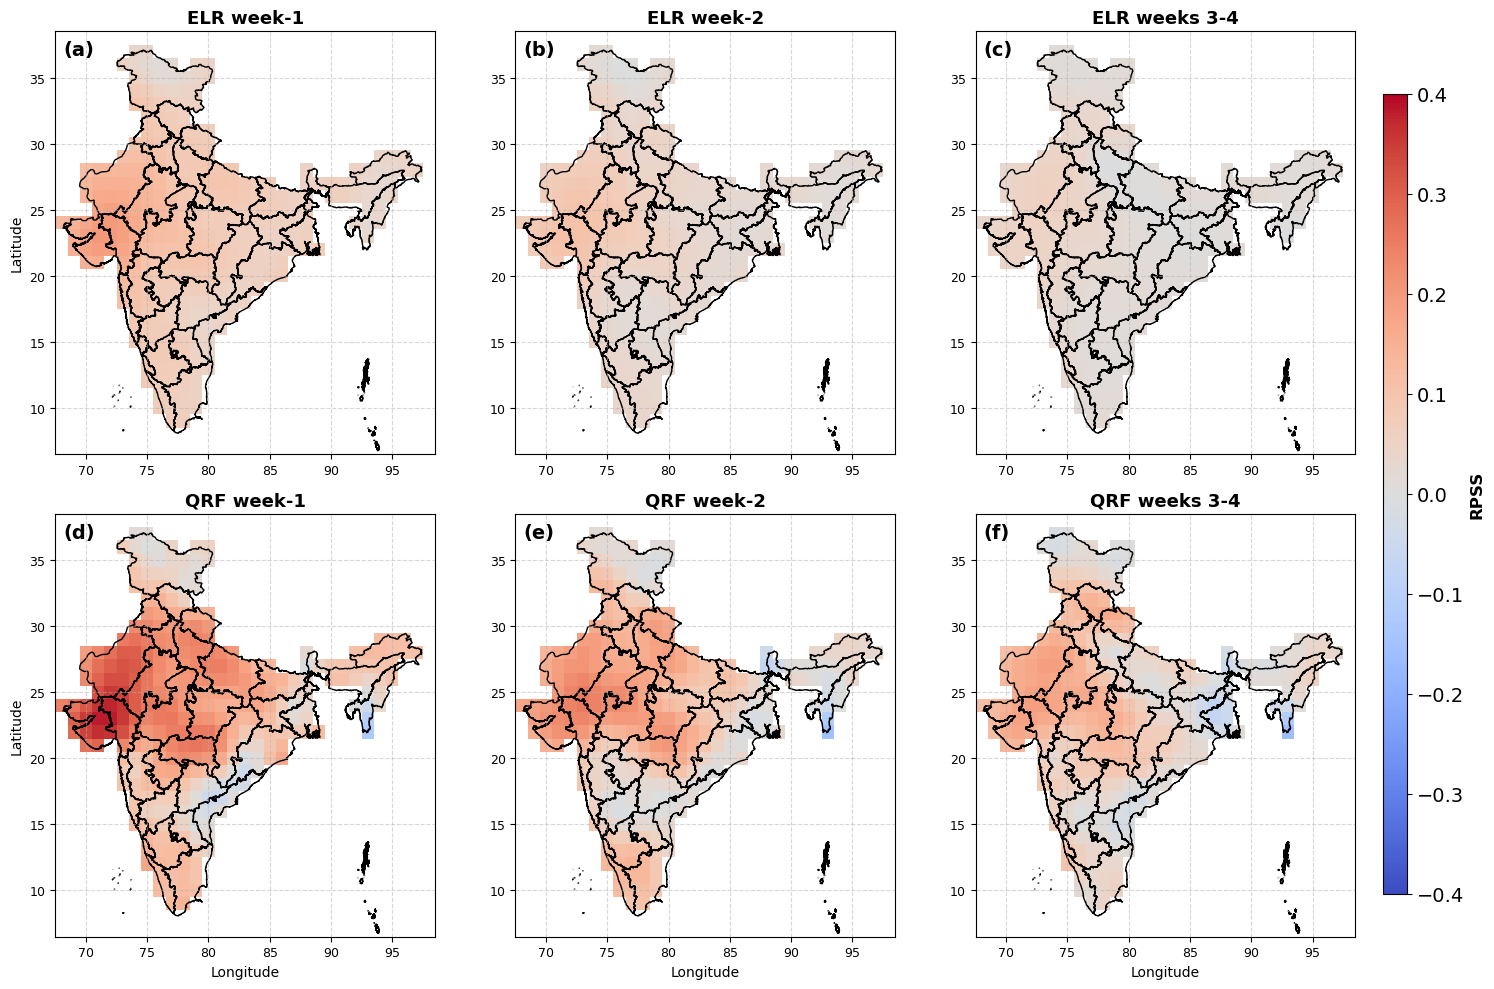

In [9]:
# Create 2x3 subplot figure
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))
axes = axes.flatten()  # Flatten to easily loop through

# Loop over each variable and corresponding axis
for i, (var_name, title) in enumerate(zip(rpss_var, titles)):
    ax = axes[i]
    
    # Access the variable from globals or locals
    smoothed_data = globals()[var_name]  # or use locals()[var_name] if defined locally

    # Plot without automatic colorbar
    smoothed_plot = smoothed_data.plot(
        ax=ax,
        cmap="coolwarm",
        vmin=-0.4,
        vmax=0.4,
        add_colorbar=False
    )

    # Overlay shapefile
    gdf_st.plot(ax=ax, color="none", edgecolor="black", linewidth=1)

    # Set subplot title
    ax.set_title(title, fontsize=13, weight='bold')
    #ax.set_xlabel("Longitude", fontsize=10)
    #ax.set_ylabel("Latitude", fontsize=10)
    ax.tick_params(axis='both', labelsize=9)
    ax.grid(True, linestyle="--", alpha=0.5)
    # Add labels (a), (b), (c), ... in the top-left corner
    ax.text(0.02, 0.98, f"({chr(97 + i)})", transform=ax.transAxes, 
            fontsize=14, weight='bold', va='top', ha='left', color='black')
    
for i in range(1, 7):  # Subplot numbers from 1 to 6
    ax = axes[i - 1]  # Access subplot from axes array (0-based indexing)

    # Latitude labels on subplot 1 and 4
    if i in [1, 4]:
        ax.set_ylabel("Latitude")
    else:
        ax.set_ylabel("")

    # Longitude labels on subplot 4, 5, 6
    if i in [4, 5, 6]:
        ax.set_xlabel("Longitude")
    else:
        ax.set_xlabel("")
        
# Add a single colorbar to the right
cbar_ax = fig.add_axes([0.88, 0.1, 0.015, 0.8])  # [left, bottom, width, height]
cbar = fig.colorbar(smoothed_plot, cax=cbar_ax)
cbar.set_label("RPSS", fontsize=12, fontweight ='bold')
cbar.ax.tick_params(labelsize=14)
# Adjust layout
plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space on right for colorbar

# Save the figure as a PDF with high DPI (300 dpi is typical for publication)
plt.savefig("/Users/bohar/Documents/abstract_papers/QRF/figures/rpss_plot.pdf", format="pdf", dpi=300)

# Optionally, you can also save in PNG format if needed:
# plt.savefig("smoothed_rpss_plot.png", format="png", dpi=300)
# Show plot
plt.show()


In [13]:
# =========================================================
# DOMAIN-AVERAGE RPSS FROM EXISTING RPSS FIELDS
# =========================================================

# QRF
qrf_rpss_domain = {
    1: float(qrf_rpss_week1.mean(skipna=True)),
    2: float(qrf_rpss_week2.mean(skipna=True)),
    34: float(qrf_rpss_week34.mean(skipna=True))
}

# ELR
elr_rpss_domain = {
    1: float(elr_rpss_week1.mean(skipna=True)),
    2: float(elr_rpss_week2.mean(skipna=True)),
    34: float(elr_rpss_week34.mean(skipna=True))
}

# Difference: positive means QRF has higher RPSS
rpss_diff_domain = {
    week: qrf_rpss_domain[week] - elr_rpss_domain[week]
    for week in weekn
}

# Print values
for week in weekn:
    print(
        f"Week {week}: "
        f"QRF RPSS = {qrf_rpss_domain[week]:.4f}, "
        f"ELR RPSS = {elr_rpss_domain[week]:.4f}, "
        f"QRF-ELR = {rpss_diff_domain[week]:+.4f}"
    )

Week 1: QRF RPSS = 0.1387, ELR RPSS = 0.0822, QRF-ELR = +0.0566
Week 2: QRF RPSS = 0.0893, ELR RPSS = 0.0411, QRF-ELR = +0.0482
Week 34: QRF RPSS = 0.0590, ELR RPSS = 0.0220, QRF-ELR = +0.0370


/var/folders/34/fdq0mjln3bq45ggl8td4163c0000gp/T/ipykernel_34111/3541228976.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


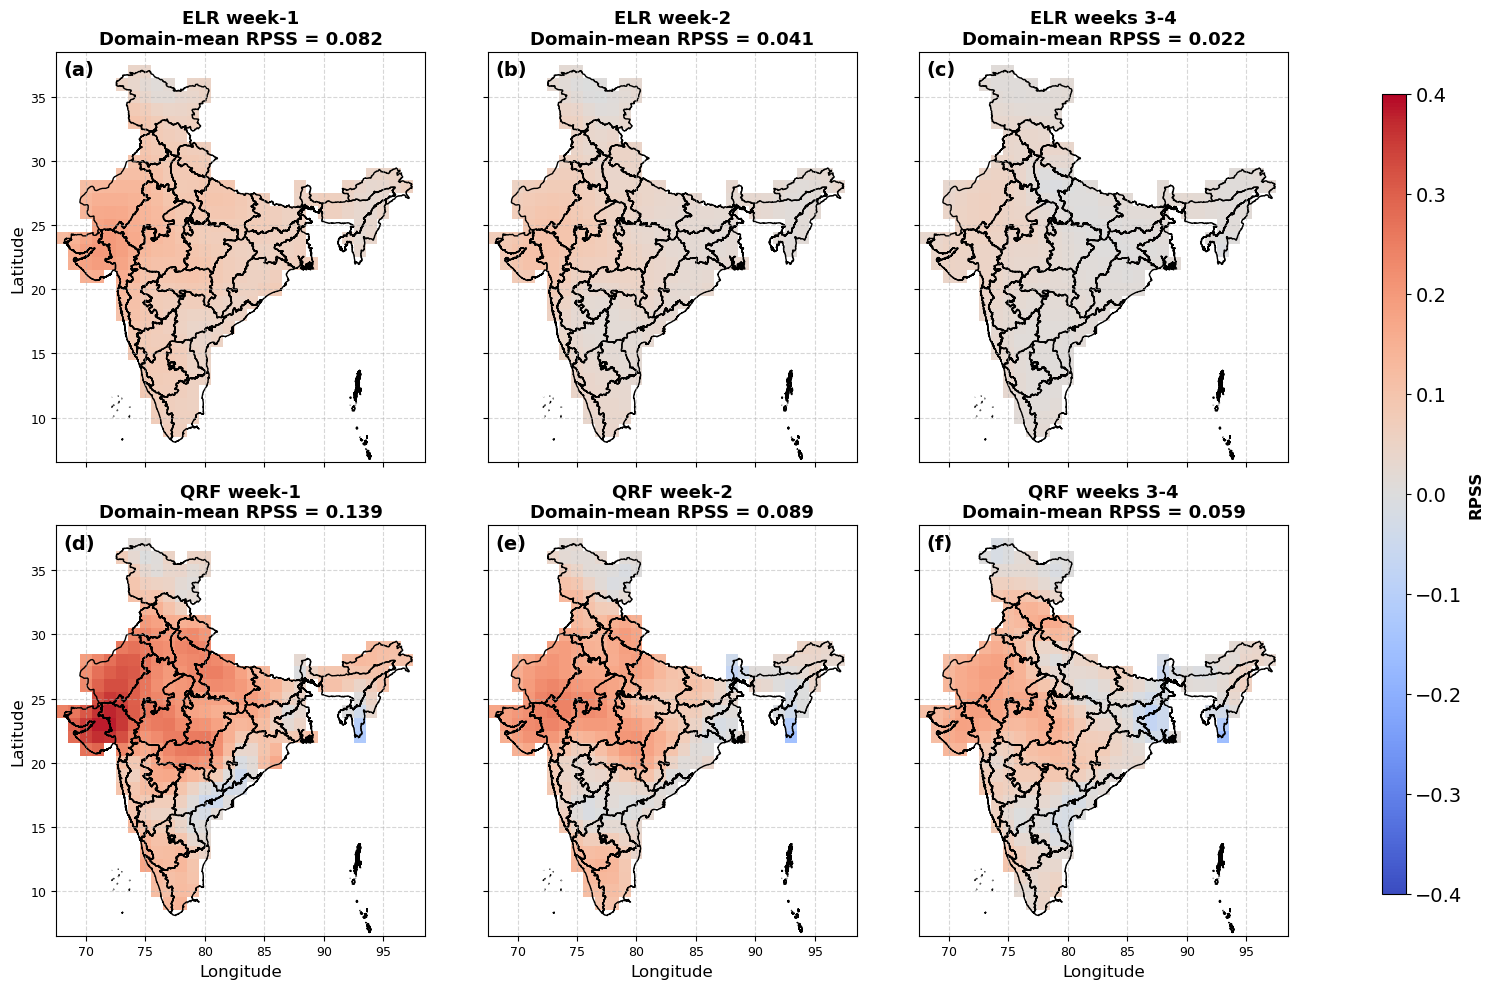

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# =========================================================
# RPSS VARIABLES
# =========================================================

# Smoothed variables used for plotting
rpss_var = [
    'smelr_rpss_week1',
    'smelr_rpss_week2',
    'smelr_rpss_week34',
    'smqrf_rpss_week1',
    'smqrf_rpss_week2',
    'smqrf_rpss_week34'
]

# Corresponding UNSMOOTHED variables used for domain averages
rpss_unsmoothed_var = [
    'elr_rpss_week1',
    'elr_rpss_week2',
    'elr_rpss_week34',
    'qrf_rpss_week1',
    'qrf_rpss_week2',
    'qrf_rpss_week34'
]

titles = [
    'ELR week-1',
    'ELR week-2',
    'ELR weeks 3-4',
    'QRF week-1',
    'QRF week-2',
    'QRF weeks 3-4'
]


# =========================================================
# CREATE FIGURE
# =========================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 10),
    sharex=True,
    sharey=True
)

axes = axes.flatten()


# =========================================================
# LOOP THROUGH PANELS
# =========================================================

for i, (smooth_name, raw_name, title) in enumerate(
    zip(rpss_var, rpss_unsmoothed_var, titles)
):

    ax = axes[i]

    # -----------------------------------------------------
    # Access smoothed field for plotting
    # -----------------------------------------------------
    smoothed_data = globals()[smooth_name]

    # -----------------------------------------------------
    # Access unsmoothed field for domain-average RPSS
    # -----------------------------------------------------
    raw_data = globals()[raw_name]

    # -----------------------------------------------------
    # Calculate domain-average RPSS
    # -----------------------------------------------------
    # Works for xarray.DataArray or numpy array
    if hasattr(raw_data, "mean") and hasattr(raw_data, "dims"):
        domain_mean_rpss = raw_data.mean(
            skipna=True
        ).item()
    else:
        domain_mean_rpss = np.nanmean(raw_data)


    # -----------------------------------------------------
    # Plot RPSS map
    # -----------------------------------------------------
    smoothed_plot = smoothed_data.plot(
        ax=ax,
        cmap="coolwarm",
        vmin=-0.4,
        vmax=0.4,
        add_colorbar=False
    )


    # -----------------------------------------------------
    # Overlay shapefile
    # -----------------------------------------------------
    gdf_st.plot(
        ax=ax,
        color="none",
        edgecolor="black",
        linewidth=1
    )


    # -----------------------------------------------------
    # Title + domain-average RPSS
    # -----------------------------------------------------
    ax.set_title(
        f'{title}\n'
        f'Domain-mean RPSS = {domain_mean_rpss:.3f}',
        fontsize=13,
        weight='bold'
    )


    # -----------------------------------------------------
    # Tick settings
    # -----------------------------------------------------
    ax.tick_params(
        axis='both',
        labelsize=9
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.5
    )


    # -----------------------------------------------------
    # Panel labels: (a), (b), ...
    # -----------------------------------------------------
    ax.text(
        0.02,
        0.98,
        f"({chr(97 + i)})",
        transform=ax.transAxes,
        fontsize=14,
        weight='bold',
        va='top',
        ha='left',
        color='black'
    )


# =========================================================
# AXIS LABELS
# =========================================================

for i in range(1, 7):

    ax = axes[i - 1]

    # Latitude labels only on panels 1 and 4
    if i in [1, 4]:
        ax.set_ylabel(
            "Latitude",
            fontsize=12
        )
    else:
        ax.set_ylabel("")

    # Longitude labels only on panels 4, 5, 6
    if i in [4, 5, 6]:
        ax.set_xlabel(
            "Longitude",
            fontsize=12
        )
    else:
        ax.set_xlabel("")


# =========================================================
# COLORBAR
# =========================================================

cbar_ax = fig.add_axes(
    [0.88, 0.1, 0.015, 0.8]
)

cbar = fig.colorbar(
    smoothed_plot,
    cax=cbar_ax
)

cbar.set_label(
    "RPSS",
    fontsize=12,
    fontweight='bold'
)

cbar.ax.tick_params(
    labelsize=14
)


# =========================================================
# LAYOUT
# =========================================================

plt.tight_layout(
    rect=[0, 0, 0.86, 1]
)


# =========================================================
# SAVE FIGURE
# =========================================================

plt.savefig(
    "/Users/bohar/Documents/abstract_papers/QRF/figures/rpss_plot_nov26.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


--------------------------------------
week-1
--------------------------------------
ELR domain-mean RPSS = 0.0822
QRF domain-mean RPSS = 0.1387
QRF - ELR difference = +0.0566
QRF RPSS > ELR RPSS: 233/315 grid points (74.0%)
ELR RPSS > QRF RPSS: 82/315 grid points (26.0%)
Equal: 0/315 grid points (0.0%)

--------------------------------------
week-2
--------------------------------------
ELR domain-mean RPSS = 0.0411
QRF domain-mean RPSS = 0.0893
QRF - ELR difference = +0.0482
QRF RPSS > ELR RPSS: 225/315 grid points (71.4%)
ELR RPSS > QRF RPSS: 90/315 grid points (28.6%)
Equal: 0/315 grid points (0.0%)

--------------------------------------
weeks 3-4
--------------------------------------
ELR domain-mean RPSS = 0.0220
QRF domain-mean RPSS = 0.0590
QRF - ELR difference = +0.0370
QRF RPSS > ELR RPSS: 224/315 grid points (71.1%)
ELR RPSS > QRF RPSS: 91/315 grid points (28.9%)
Equal: 0/315 grid points (0.0%)


/var/folders/34/fdq0mjln3bq45ggl8td4163c0000gp/T/ipykernel_34111/2102257071.py:439: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


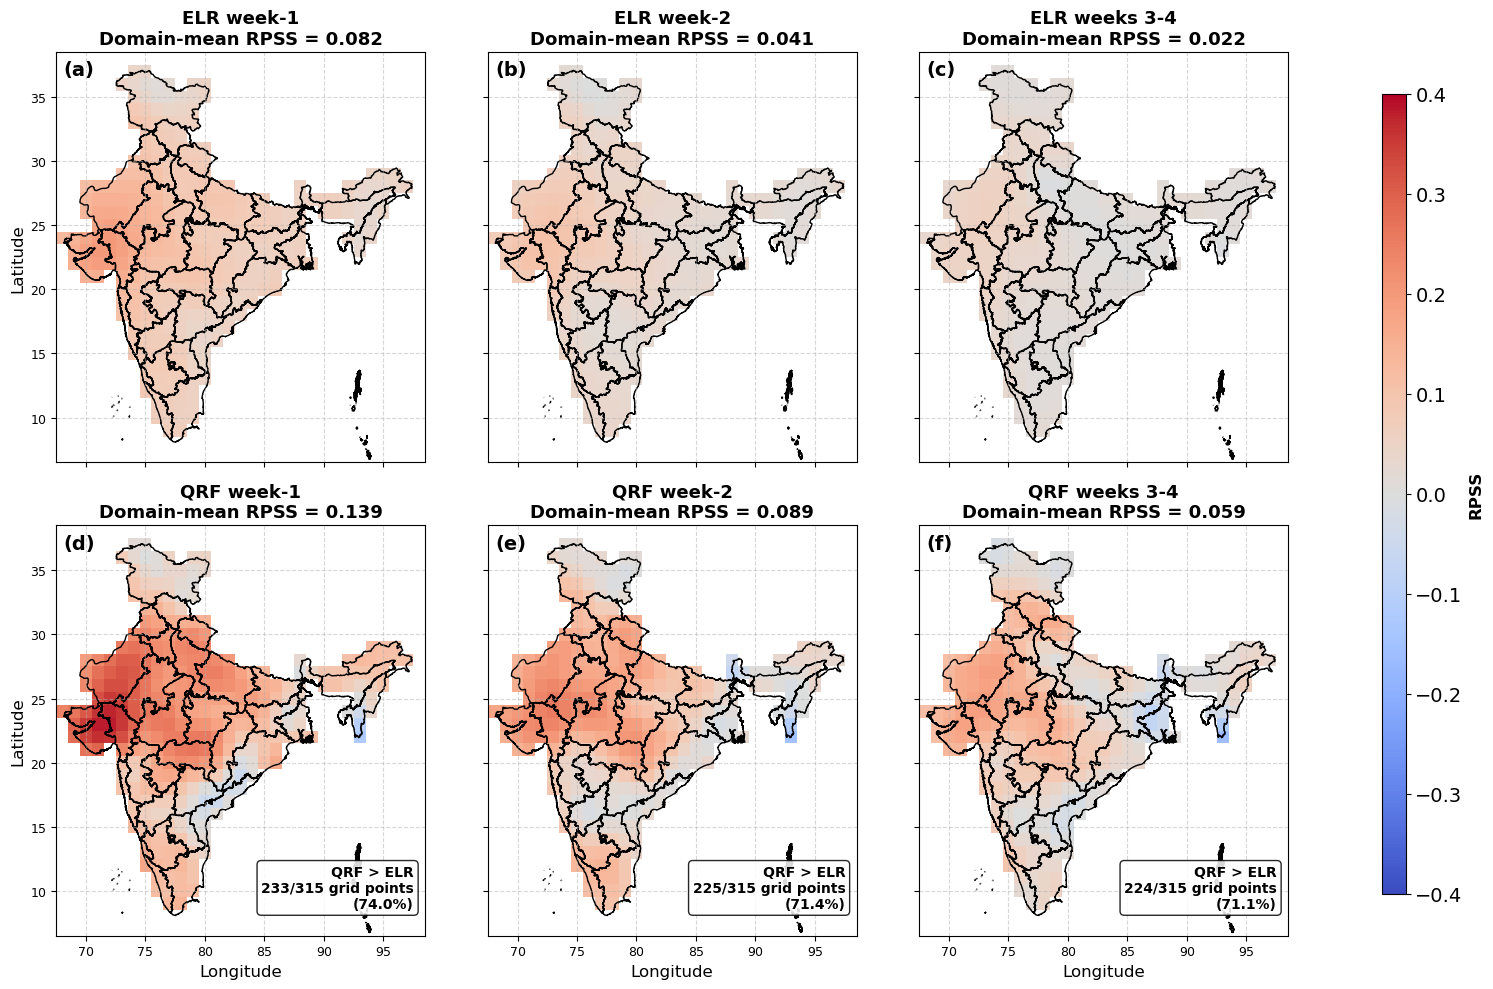

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# =========================================================
# RPSS VARIABLES
# =========================================================

# Smoothed variables used for plotting
rpss_var = [
    'smelr_rpss_week1',
    'smelr_rpss_week2',
    'smelr_rpss_week34',
    'smqrf_rpss_week1',
    'smqrf_rpss_week2',
    'smqrf_rpss_week34'
]

# Corresponding UNSMOOTHED variables used for domain averages
rpss_unsmoothed_var = [
    'elr_rpss_week1',
    'elr_rpss_week2',
    'elr_rpss_week34',
    'qrf_rpss_week1',
    'qrf_rpss_week2',
    'qrf_rpss_week34'
]

titles = [
    'ELR week-1',
    'ELR week-2',
    'ELR weeks 3-4',
    'QRF week-1',
    'QRF week-2',
    'QRF weeks 3-4'
]

# =========================================================
# HELPER FUNCTION
# =========================================================

def to_numpy(data):
    """
    Convert xarray.DataArray or numpy-like object to numpy array.
    """
    if hasattr(data, "values"):
        return data.values
    return np.asarray(data)


# =========================================================
# CALCULATE QRF > ELR GRID-POINT STATISTICS
# USING UNSMOOTHED RPSS FIELDS
# =========================================================

week_pairs = {
    'week-1': (
        globals()['elr_rpss_week1'],
        globals()['qrf_rpss_week1']
    ),

    'week-2': (
        globals()['elr_rpss_week2'],
        globals()['qrf_rpss_week2']
    ),

    'weeks 3-4': (
        globals()['elr_rpss_week34'],
        globals()['qrf_rpss_week34']
    )
}

comparison_results = {}

for week_label, (elr_raw, qrf_raw) in week_pairs.items():

    elr_values = to_numpy(elr_raw)
    qrf_values = to_numpy(qrf_raw)

    # -----------------------------------------------------
    # Valid points where BOTH methods have finite RPSS
    # -----------------------------------------------------
    valid_mask = (
        np.isfinite(elr_values)
        & np.isfinite(qrf_values)
    )

    total_valid_points = int(
        np.sum(valid_mask)
    )

    # -----------------------------------------------------
    # RPSS: HIGHER IS BETTER
    # -----------------------------------------------------
    qrf_better_points = int(
        np.sum(
            (qrf_values > elr_values)
            & valid_mask
        )
    )

    elr_better_points = int(
        np.sum(
            (elr_values > qrf_values)
            & valid_mask
        )
    )

    equal_points = int(
        np.sum(
            np.isclose(
                qrf_values,
                elr_values,
                atol=1e-12
            )
            & valid_mask
        )
    )

    # -----------------------------------------------------
    # Percentages
    # -----------------------------------------------------
    percent_qrf_better = (
        100.0 * qrf_better_points / total_valid_points
        if total_valid_points > 0
        else np.nan
    )

    percent_elr_better = (
        100.0 * elr_better_points / total_valid_points
        if total_valid_points > 0
        else np.nan
    )

    percent_equal = (
        100.0 * equal_points / total_valid_points
        if total_valid_points > 0
        else np.nan
    )

    # -----------------------------------------------------
    # Domain means
    # -----------------------------------------------------
    domain_mean_elr = np.nanmean(
        elr_values
    )

    domain_mean_qrf = np.nanmean(
        qrf_values
    )

    domain_mean_diff = (
        domain_mean_qrf
        - domain_mean_elr
    )

    # -----------------------------------------------------
    # Store results
    # -----------------------------------------------------
    comparison_results[week_label] = {
        'ELR_mean': domain_mean_elr,
        'QRF_mean': domain_mean_qrf,
        'QRF_minus_ELR': domain_mean_diff,
        'valid_points': total_valid_points,
        'QRF_better_points': qrf_better_points,
        'ELR_better_points': elr_better_points,
        'equal_points': equal_points,
        'QRF_better_percent': percent_qrf_better,
        'ELR_better_percent': percent_elr_better,
        'equal_percent': percent_equal
    }

    # -----------------------------------------------------
    # Print results
    # -----------------------------------------------------
    print("\n--------------------------------------")
    print(week_label)
    print("--------------------------------------")

    print(
        f"ELR domain-mean RPSS = "
        f"{domain_mean_elr:.4f}"
    )

    print(
        f"QRF domain-mean RPSS = "
        f"{domain_mean_qrf:.4f}"
    )

    print(
        f"QRF - ELR difference = "
        f"{domain_mean_diff:+.4f}"
    )

    print(
        f"QRF RPSS > ELR RPSS: "
        f"{qrf_better_points}/{total_valid_points} "
        f"grid points ({percent_qrf_better:.1f}%)"
    )

    print(
        f"ELR RPSS > QRF RPSS: "
        f"{elr_better_points}/{total_valid_points} "
        f"grid points ({percent_elr_better:.1f}%)"
    )

    print(
        f"Equal: "
        f"{equal_points}/{total_valid_points} "
        f"grid points ({percent_equal:.1f}%)"
    )


# =========================================================
# CREATE FIGURE
# =========================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 10),
    sharex=True,
    sharey=True
)

axes = axes.flatten()


# =========================================================
# MAP EACH PANEL TO ITS LEAD-TIME COMPARISON
# =========================================================

panel_week_labels = [
    'week-1',
    'week-2',
    'weeks 3-4',
    'week-1',
    'week-2',
    'weeks 3-4'
]


# =========================================================
# LOOP THROUGH PANELS
# =========================================================

for i, (smooth_name, raw_name, title, week_label) in enumerate(
    zip(
        rpss_var,
        rpss_unsmoothed_var,
        titles,
        panel_week_labels
    )
):

    ax = axes[i]

    # -----------------------------------------------------
    # Access smoothed field for plotting
    # -----------------------------------------------------
    smoothed_data = globals()[smooth_name]

    # -----------------------------------------------------
    # Access unsmoothed field for domain-average RPSS
    # -----------------------------------------------------
    raw_data = globals()[raw_name]

    raw_values = to_numpy(raw_data)

    # -----------------------------------------------------
    # Domain-average RPSS
    # -----------------------------------------------------
    domain_mean_rpss = np.nanmean(
        raw_values
    )

    # -----------------------------------------------------
    # Plot RPSS map
    # -----------------------------------------------------
    smoothed_plot = smoothed_data.plot(
        ax=ax,
        cmap="coolwarm",
        vmin=-0.4,
        vmax=0.4,
        add_colorbar=False
    )

    # -----------------------------------------------------
    # Overlay shapefile
    # -----------------------------------------------------
    gdf_st.plot(
        ax=ax,
        color="none",
        edgecolor="black",
        linewidth=1
    )

    # -----------------------------------------------------
    # Title + domain-average RPSS
    # -----------------------------------------------------
    ax.set_title(
        f'{title}\n'
        f'Domain-mean RPSS = {domain_mean_rpss:.3f}',
        fontsize=13,
        weight='bold'
    )

    # -----------------------------------------------------
    # Add QRF > ELR count/percentage
    # ONLY TO QRF PANELS
    # -----------------------------------------------------
    if i >= 3:

        result = comparison_results[
            week_label
        ]

        qrf_better_points = result[
            'QRF_better_points'
        ]

        total_valid_points = result[
            'valid_points'
        ]

        percent_qrf_better = result[
            'QRF_better_percent'
        ]

        ax.text(
            0.97,
            0.06,
            f'QRF > ELR\n'
            f'{qrf_better_points}/{total_valid_points} grid points\n'
            f'({percent_qrf_better:.1f}%)',
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            ha='right',
            va='bottom',
            bbox=dict(
                facecolor='white',
                edgecolor='black',
                alpha=0.85,
                boxstyle='round,pad=0.3'
            )
        )

    # -----------------------------------------------------
    # Tick settings
    # -----------------------------------------------------
    ax.tick_params(
        axis='both',
        labelsize=9
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.5
    )

    # -----------------------------------------------------
    # Panel labels: (a), (b), ...
    # -----------------------------------------------------
    ax.text(
        0.02,
        0.98,
        f"({chr(97 + i)})",
        transform=ax.transAxes,
        fontsize=14,
        weight='bold',
        va='top',
        ha='left',
        color='black'
    )


# =========================================================
# AXIS LABELS
# =========================================================

for i in range(1, 7):

    ax = axes[i - 1]

    # Latitude labels only on panels 1 and 4
    if i in [1, 4]:

        ax.set_ylabel(
            "Latitude",
            fontsize=12
        )

    else:

        ax.set_ylabel("")

    # Longitude labels only on panels 4, 5, 6
    if i in [4, 5, 6]:

        ax.set_xlabel(
            "Longitude",
            fontsize=12
        )

    else:

        ax.set_xlabel("")


# =========================================================
# COLORBAR
# =========================================================

cbar_ax = fig.add_axes(
    [0.88, 0.1, 0.015, 0.8]
)

cbar = fig.colorbar(
    smoothed_plot,
    cax=cbar_ax
)

cbar.set_label(
    "RPSS",
    fontsize=12,
    fontweight='bold'
)

cbar.ax.tick_params(
    labelsize=14
)


# =========================================================
# LAYOUT
# =========================================================

plt.tight_layout(
    rect=[0, 0, 0.86, 1]
)


# =========================================================
# SAVE FIGURE
# =========================================================

plt.savefig(
    "/Users/bohar/Documents/abstract_papers/QRF/"
    "figures/rpss_plot_nov26.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()